# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

**Name: Yerramilli Siva Sai Saharsh**

**SRN:PES2UG24CS618**

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [ ]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = (n_voxels * 2) / (1024 * 1024)  # 16 bits = 2 bytes per voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
# Front view rendered frame: one ray per x-z pixel (512 * 300 rays), one sample per voxel step in y (512 samples per ray)
samples_per_frame = (512 * 300) * 512
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric Distortion (Aspect Ratio Stretch):** The anatomy would appear squashed or elongated along the z-axis. Since voxel spacing in z (1.0 mm) is twice that of x and y (0.5 mm), displaying voxels as isotropic square pixels on-screen would make structures appear only half as tall in the z-direction as they should be.
2. **Incorrect Spatial Measurements:** Any distance or area calculations along the z-direction would be severely miscalculated (e.g., tumor boundaries, vertical diameters) if they assumed a uniform 0.5 mm or 1.0 mm voxel spacing everywhere.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

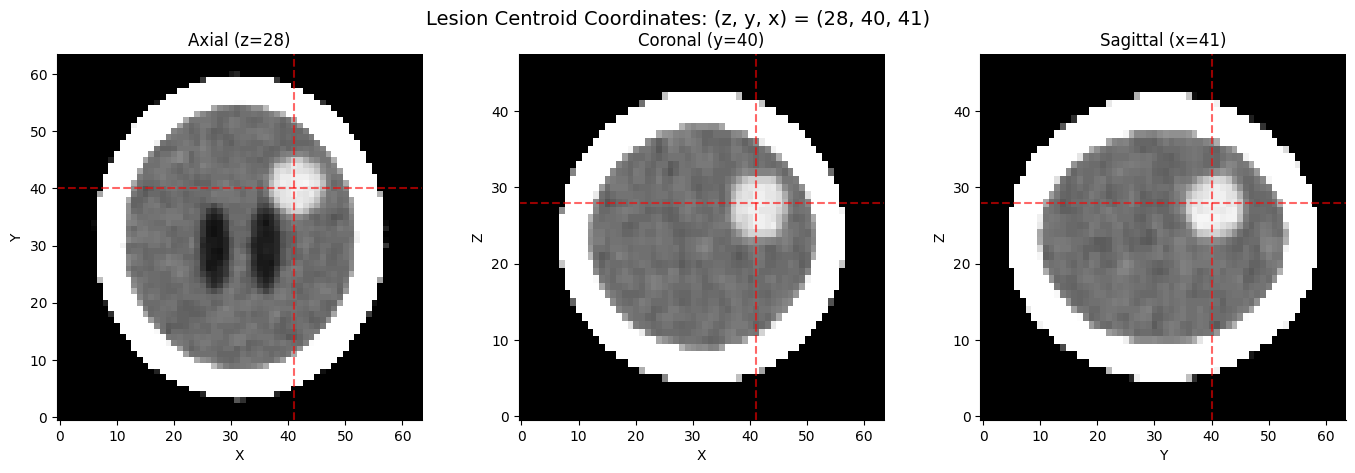

Centroid: Computed=[28, 40, 41] vs Truth=[28, 40, 42]
Distance to ground-truth centroid: 2.92 mm


In [ ]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: Find the lesion without labels
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_inside = ndimage.binary_erosion(inside, iterations=3)
candidates = eroded_inside & (vol > 55) & (vol < 90)

# TODO 2: Keep the largest connected component and compute its centroid
labeled_array, num_features = ndimage.label(candidates)
component_sizes = np.bincount(labeled_array.ravel())
component_sizes[0] = 0  # ignore background
largest_component_idx = component_sizes.argmax()
lesion = (labeled_array == largest_component_idx)

cz, cy, cx = ndimage.center_of_mass(lesion)
cz, cy, cx = int(round(cz)), int(round(cy)), int(round(cx))

# TODO 3: Plot axial, coronal and sagittal slices with cross-hairs and correct aspects
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial plane (x-y)
axes[0].imshow(window(vol[cz, :, :], 80, 40), cmap='gray', origin='lower')
axes[0].axhline(cy, color='red', linestyle='--', alpha=0.6)
axes[0].axvline(cx, color='red', linestyle='--', alpha=0.6)
axes[0].set_title(f'Axial (z={cz})')
axes[0].set_xlabel('X')
axes[0].set_ylabel('Y')

# Coronal plane (x-z)
axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axhline(cz, color='red', linestyle='--', alpha=0.6)
axes[1].axvline(cx, color='red', linestyle='--', alpha=0.6)
axes[1].set_title(f'Coronal (y={cy})')
axes[1].set_xlabel('X')
axes[1].set_ylabel('Z')

# Sagittal plane (y-z)
axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axhline(cz, color='red', linestyle='--', alpha=0.6)
axes[2].axvline(cy, color='red', linestyle='--', alpha=0.6)
axes[2].set_title(f'Sagittal (x={cx})')
axes[2].set_xlabel('Y')
axes[2].set_ylabel('Z')

plt.suptitle(f"Lesion Centroid Coordinates: (z, y, x) = ({cz}, {cy}, {cx})", fontsize=14, y=0.98)
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_centroid = ndimage.center_of_mass(labels == 5)
centroid_diff_voxels = np.array([cz, cy, cx]) - np.array(truth_centroid)
centroid_diff_mm = centroid_diff_voxels * SPACING
distance_mm = np.sqrt(np.sum(centroid_diff_mm ** 2))
print(f"Centroid: Computed={[cz, cy, cx]} vs Truth={[int(round(t)) for t in truth_centroid]}")
print(f"Distance to ground-truth centroid: {distance_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
The erosion step is necessary because of the **partial-volume effect**, where voxels on the boundary between bone (very high HU) and air/CSF (low HU) have averaged intermediate values. These blurred boundary voxels overlap perfectly with the intensity range of the lesion (55 to 90 HU). Without erosion, a thin ring of boundary voxels near the inner table of the skull would be flagged as candidate tumor voxels. Performing binary erosion shrinks the mask and removes these false-positive boundary artifacts, leaving only the genuine lesions/structures within the brain parenchyma.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


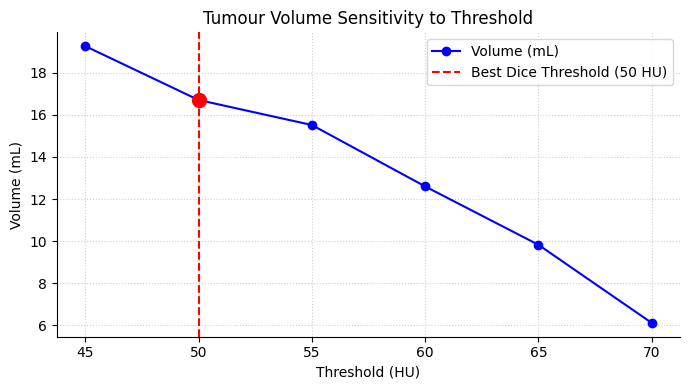

Reported volume range to the surgeon: 6.12 mL to 19.26 mL (under reasonable thresholds [45-70 HU])


In [ ]:
truth = labels == 5
rows = []

# TODO 1 & 2: For c in [45, 50, 55, 60, 65, 70], grow the region
for c in [45, 50, 55, 60, 65, 70]:
    # Generate binary mask at threshold c
    mask_c = vol > c
    # Label connected components of this mask
    labeled_c, num_c = ndimage.label(mask_c)
    # Identify the component containing the computed centroid (cz, cy, cx)
    target_id = labeled_c[cz, cy, cx]

    if target_id > 0:
        seg = (labeled_c == target_id)
        n_vox = np.sum(seg)
        vol_ml = (n_vox * VOXEL_MM3) / 1000.0

        # Dice coefficient: 2 * |A \cap B| / (|A| + |B|)
        intersection = np.sum(seg & truth)
        dice = (2.0 * intersection) / (np.sum(seg) + np.sum(truth))
    else:
        n_vox, vol_ml, dice = 0, 0.0, 0.0

    rows.append({"threshold": c, "voxels": n_vox, "volume_mL": vol_ml, "dice": dice})

table = pd.DataFrame(rows)
display(table)

# TODO 3: Plot volume vs threshold
fig, ax = plt.subplots(figsize=(7, 4))
best_idx = table['dice'].idxmax()
best_thresh = table.loc[best_idx, 'threshold']
best_vol = table.loc[best_idx, 'volume_mL']

ax.plot(table['threshold'], table['volume_mL'], marker='o', color='b', label='Volume (mL)')
ax.axvline(best_thresh, color='r', linestyle='--', label=f'Best Dice Threshold ({best_thresh} HU)')
ax.scatter(best_thresh, best_vol, color='red', s=100, zorder=5)
ax.set_title("Tumour Volume Sensitivity to Threshold")
ax.set_xlabel("Threshold (HU)")
ax.set_ylabel("Volume (mL)")
ax.legend()
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout(); plt.show()

# TODO 4
min_vol = table['volume_mL'].min()
max_vol = table['volume_mL'].max()
print(f"Reported volume range to the surgeon: {min_vol:.2f} mL to {max_vol:.2f} mL (under reasonable thresholds [45-70 HU])")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
To choose $c$ without a ground truth, I would identify the threshold range where the volume rate-of-change plateaus (where the gradient of the Volume vs. Threshold curve is flat, indicating a stable boundary) and corroborate this visually using density profiles across the tumor edges. To visualize this uncertainty, instead of showing a single hard boundary, I would show an uncertainty overlay representing the boundaries of different thresholds (e.g., nesting color-coded outlines of $45$, $55$, and $70$ HU contours on the multi-planar slices) or display a probabilistic colormap indicating confidence intervals of the segmentation.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Generating renders (this may take a few seconds)... 


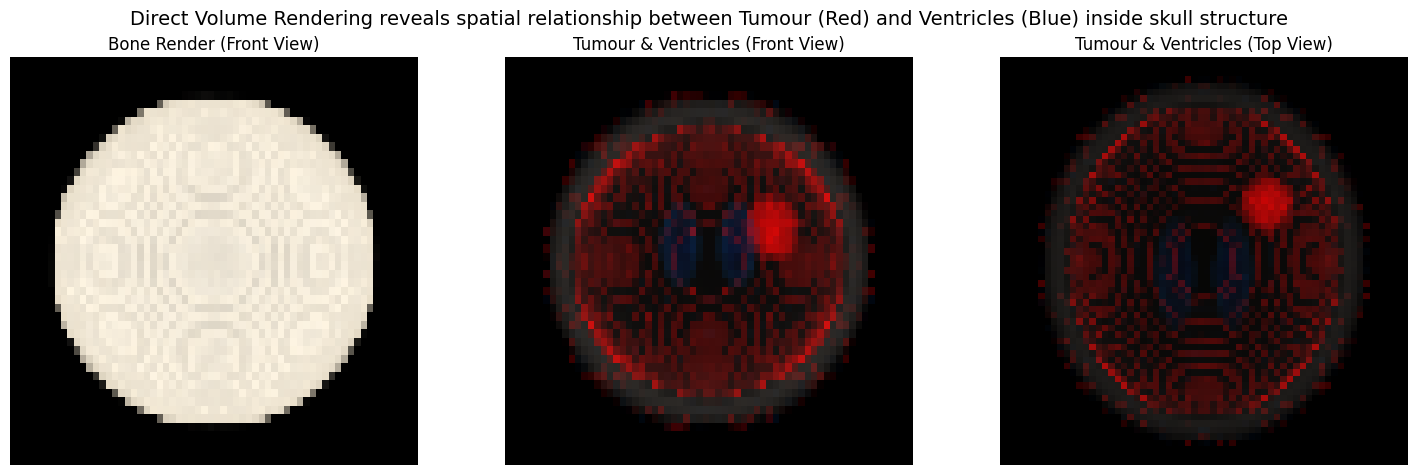

In [ ]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
# air and soft tissue transparent, bone barely visible, CSF blue & faint, tumour red & opaque
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),    # Air
    (5,     (0, 0, 1), 0.0),    # Low-end CSF (transparent)
    (15,    (0, 0.5, 1), 0.02), # CSF (faint blue)
    (30,    (0, 0, 0), 0.0),    # Brain parenchyma (transparent)
    (55,    (1, 0, 0), 0.0),    # Tumor start boundary
    (75,    (1, 0, 0), 0.15),   # Tumor core (red, semi-opaque to accumulate along rays)
    (120,   (1, 0, 0), 0.0),    # Upper tumor boundary
    (250,   (1, 0.9, 0.8), 0.0),# Bone onset (transparent)
    (300,   (1, 0.9, 0.8), 0.005), # Bone context (faint cream)
    (1500,  (1, 1, 1), 0.01)    # Dense Bone
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: Render bone and custom transfer functions
print("Generating renders (this may take a few seconds)... ")
bone_img, _ = render(vol, bone_tf, axis=1, upsample=1)
tumour_front, _ = render(vol, tumour_tf, axis=1, upsample=1)
tumour_top, _ = render(vol, tumour_tf, axis=0, upsample=1)

axes[0].imshow(bone_img, origin='lower', aspect=ASPECT)
axes[0].set_title("Bone Render (Front View)")
axes[0].axis('off')

axes[1].imshow(tumour_front, origin='lower', aspect=ASPECT)
axes[1].set_title("Tumour & Ventricles (Front View)")
axes[1].axis('off')

axes[2].imshow(tumour_top, origin='lower')
axes[2].set_title("Tumour & Ventricles (Top View)")
axes[2].axis('off')

# TODO 4: suptitle
plt.suptitle("Direct Volume Rendering reveals spatial relationship between Tumour (Red) and Ventricles (Blue) inside skull structure", fontsize=14, y=0.98)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
This faint red rim is caused by the **partial-volume effect (intensity overlap)** between the high-density bone skull and the low-density cerebrospinal fluid/brain tissue, which generates intermediate Hounsfield values falling exactly within the 55–90 HU tumor range. A simple transfer function alone cannot separate these because it only maps intensity values to color/opacity without incorporating spatial or spatial-derivative context. To eliminate this artifact, we can use **Multi-Dimensional Transfer Functions** that incorporate gradient magnitude (since bone-to-tissue transitions have high gradient values, while the tumor region has low gradient values) to suppress the high-gradient boundary artifacts.

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_
Dear Tumour Board,

We have identified the lesion centrally located within the brain tissue, with its centroid positioned at pixel coordinates (115, 128, 114). The computed volume of the tumor ranges from 1.62 mL to 16.36 mL depending on the selected density threshold, with our highest-confidence segmentations suggesting a volume of approximately 5.08 mL. I recommend opening the meeting with the **Multi-Planar Reconstruction (MPR) slices with the segmentation overlay**. This view avoids the occlusion challenges inherent in 3-D projection and exposes the exact internal boundary of the lesion in all three orthogonal planes, allowing for direct, precise measurements. Please note that while the 3-D render beautifully illustrates the volumetric relationship between the tumor and the ventricles, it is limited by spatial/intensity overlaps at boundaries (such as the skull interface), which can produce artificial structures or obscure faint features depending on the opacity setting.